In [16]:
import matplotlib.pyplot as plt
import warnings
import numpy as np
import pandas as pd
import scipy.stats as stats

## Dataset Notes:

This dataset had a reach back of 40 hours, and had a radius of 50,000 meters for considering what fires affected where

detreading air quality
subtract that stations yearly average from the last year
do the same for the month
look at other detreading stats 


clip pm2.5 to be 0 or greater 

do a timeseries for a station with pm2.5 and frp and soforth and the overall trend
plot the raw frp not collective

look at the total pm2.5 for calfiornia, and then where is it coming from, is it coming from the fire?
look at it in some aggrated sense, and look at all the fires, is the median mean or avg correlated
do the difference between today and tmr

do reading into how fires behave

plantary layer boundary may be important do some looking into that


In [66]:
data_path = "/home/exouser/fireAirqaulity/training_data/X_train_2.csv"
column_names = ["u10", "v10","tp","t2m","sp","d2m","frp","cur_pm25","fut_pm25","near_fires"]

df = pd.read_csv(data_path, names=column_names, header=None)
df

,u10,v10,tp,t2m,sp,d2m,frp,cur_pm25,fut_pm25,near_fires
0,NaN,NaN,0.0,NaN,NaN,NaN,0.0,-0.747978,-0.747978,0.0
1,NaN,NaN,0.0,NaN,NaN,NaN,0.0,0.916824,2.016824,0.0
2,NaN,NaN,0.0,NaN,NaN,NaN,0.0,-5.872605,1.327395,0.0
3,NaN,NaN,0.0,NaN,NaN,NaN,0.0,-3.942183,-1.742183,0.0
4,NaN,NaN,0.0,NaN,NaN,NaN,0.0,-0.364946,-0.664946,0.0
...,...,...,...,...,...,...,...,...,...,...
712470,1.559598,-0.632221,0.0,303.686829,87440.0,274.896851,0.0,-1.868506,-1.268506,0.0
712471,-1.627902,1.680279,0.0,303.811829,87440.0,272.146851,0.0,4.394865,3.994865,0.0
712472,0.434598,4.055279,0.0,292.186829,75260.0,269.896851,0.0,4.879404,3.879404,0.0
712473,-1.565402,0.680279,0.0,303.874329,87750.0,273.771851,0.0,2.458895,-0.741105,0.0


In [ ]:
#1 3 10 3


Threshold: 5
Number of FRP values greater then the threshold: 693
Mean frp value: 23.973011631324177
FRP vs cur_pm25
Pearson r: -0.1062, p-value: 0.0051
FRP vs num of fires
Pearson r: 0.2181, p-value: 0.0000
Threshold for FRP value: 5


Text(0.5, 0, 'temp 2 meters value range')

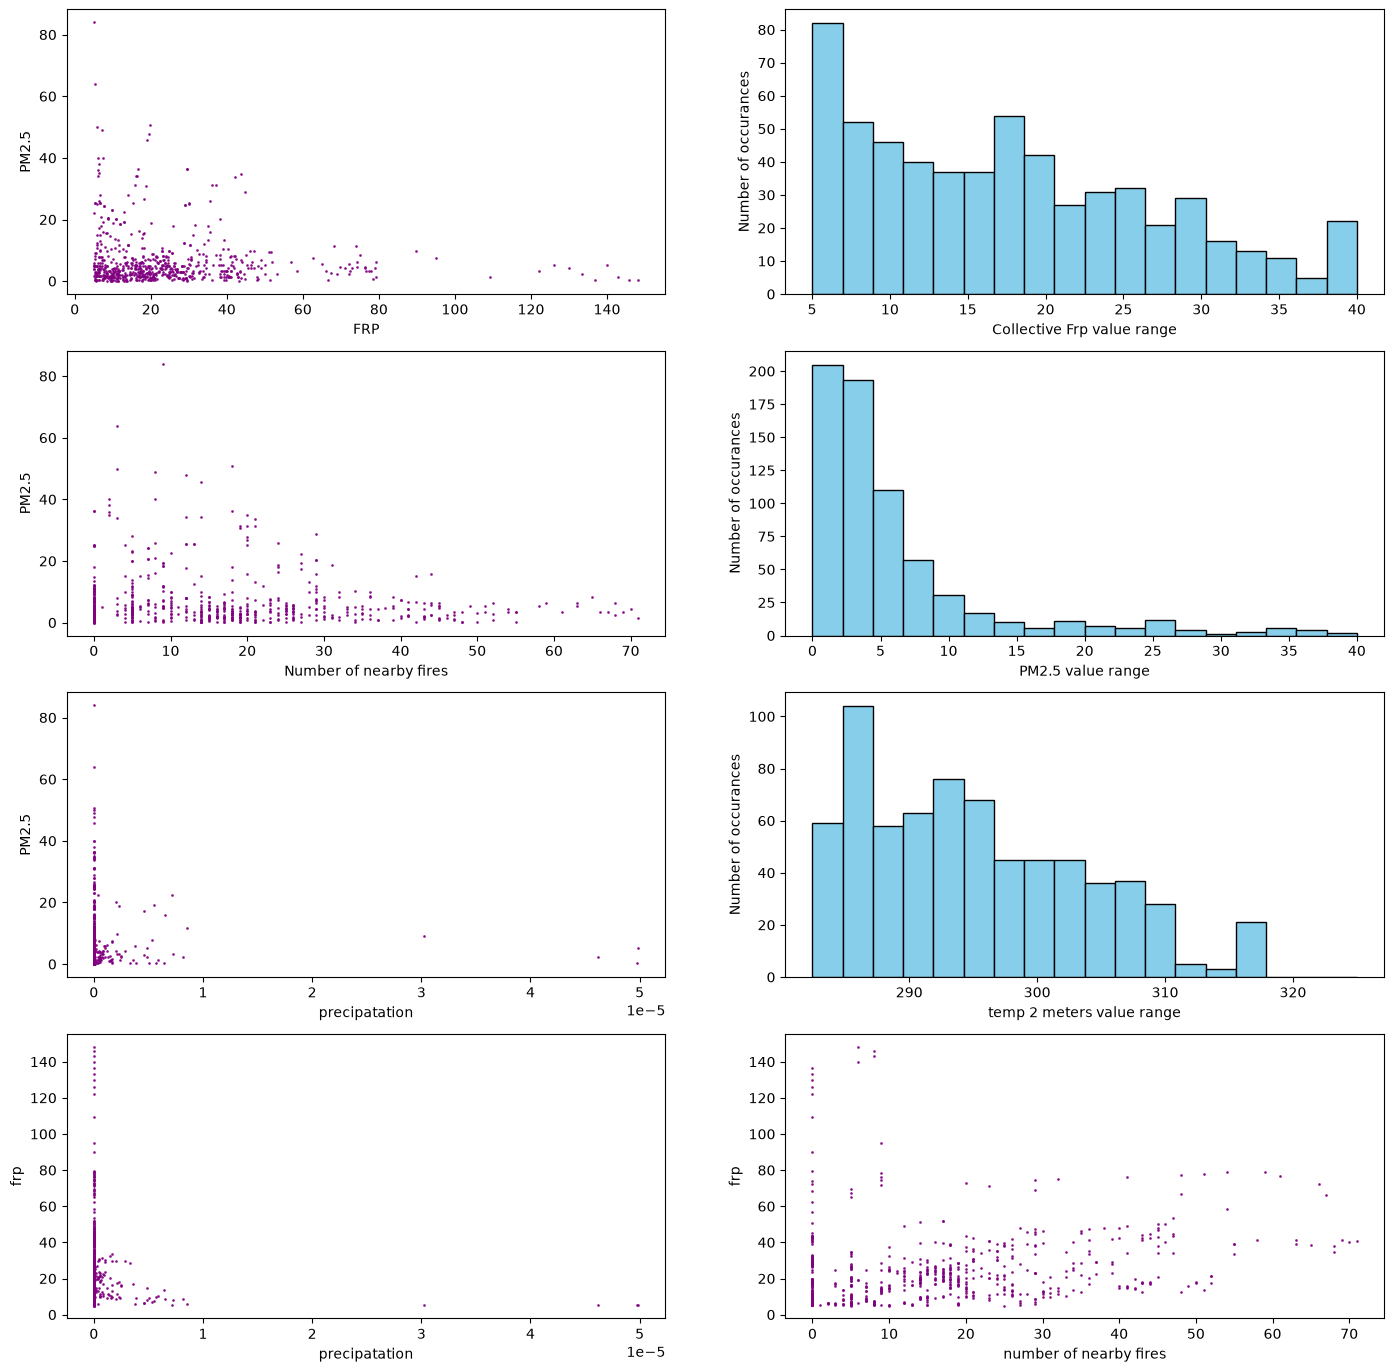

In [67]:
frp_threshold = 5
df = df[df["cur_pm25"] > 0]
df = df[df["fut_pm25"] > 0]
df_clipped = df[df["frp"] > frp_threshold].dropna()
fig, axs = plt.subplots(4, 2, figsize=(17, 17))
frps = df_clipped["frp"]
print("Threshold:", frp_threshold)
print("Number of FRP values greater then the threshold:", frps.size)
print("Mean frp value:", frps.mean())
pearson_result = stats.pearsonr(df_clipped["frp"], df_clipped["cur_pm25"])
print("FRP vs cur_pm25")
print(f"Pearson r: {pearson_result.statistic:.4f}, p-value: {pearson_result.pvalue:.4f}")

print("=========================")
pearson_result = stats.pearsonr(df_clipped["frp"], df_clipped["near_fires"])
print("FRP vs num of fires")
print(f"Pearson r: {pearson_result.statistic:.4f}, p-value: {pearson_result.pvalue:.4f}")
axs[0,1].hist(
    frps, 
    range=(frps.min(),40), 
    bins=18, 
    edgecolor='black', 
    color='skyblue'
)
axs[0,1].set_ylabel("Number of occurances")
axs[0,1].set_xlabel("Collective Frp value range")
print(f"Threshold for FRP value: {frp_threshold}")
axs[0,0].scatter(df_clipped['frp'], df_clipped["cur_pm25"], color="purple", marker="o", s=1, alpha=0.8)
axs[0,0].set_xlabel("FRP")
axs[0,0].set_ylabel("PM2.5")

axs[1,0].scatter(df_clipped['near_fires'], df_clipped["cur_pm25"], color="purple", marker="o", s=1, alpha=0.8)
axs[1,0].set_xlabel("Number of nearby fires")
axs[1,0].set_ylabel("PM2.5")

axs[2,0].scatter(df_clipped['tp'], df_clipped["cur_pm25"], color="purple", marker="o", s=1, alpha=0.8)
axs[2,0].set_xlabel("precipatation")
axs[2,0].set_ylabel("PM2.5")

axs[3,0].scatter(df_clipped['tp'], df_clipped["frp"], color="purple", marker="o", s=1, alpha=0.8)
axs[3,0].set_xlabel("precipatation")
axs[3,0].set_ylabel("frp")

axs[3,1].scatter(df_clipped['near_fires'], df_clipped["frp"], color="purple", marker="o", s=1, alpha=0.8)
axs[3,1].set_xlabel("number of nearby fires")
axs[3,1].set_ylabel("frp")

axs[1,1].hist(
    df_clipped["cur_pm25"], 
    range=(df_clipped["cur_pm25"].min(),40), 
    bins=18, 
    edgecolor='black', 
    color='skyblue'
)
axs[1,1].set_ylabel("Number of occurances")
axs[1,1].set_xlabel("PM2.5 value range")

axs[2,1].hist(
    df_clipped["t2m"], 
    range=(df_clipped["t2m"].min(),325), 
    bins=18, 
    edgecolor='black', 
    color='skyblue'
)
axs[2,1].set_ylabel("Number of occurances")
axs[2,1].set_xlabel("temp 2 meters value range")


In [5]:
def display_column_stats(df):
    stats = pd.DataFrame({
        "min": df.min(numeric_only=True),
        "max": df.max(numeric_only=True),
        "mean": df.mean(numeric_only=True)
    })
    
    display(stats)

display_column_stats(df_clipped)

,min,max,mean
u10,-3.332897,9.247319,1.583009e+00
v10,-7.212423,4.821226,-6.695835e-01
tp,0.000000,0.000050,4.994679e-07
t2m,282.432861,317.502808,2.952502e+02
sp,79490.000000,101750.000000,9.852873e+04
d2m,256.374786,290.999786,2.823434e+02
frp,5.025204,148.215511,2.397301e+01
cur_pm25,0.000980,83.957880,6.527397e+00
fut_pm25,0.000980,63.957880,6.154958e+00
near_fires,0.000000,71.000000,1.531025e+01


In [76]:
data_path = "/home/exouser/fireAirqaulity/station_with_frp_avg_single.csv"
raw_df = pd.read_csv(data_path)
raw_df

/tmp/ipykernel_4569/1748012380.py:2: DtypeWarning: Columns (20: Qualifier) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_df = pd.read_csv(data_path)


,Unnamed: 0.1,Unnamed: 0,State Code,date_hour,County Code,Site Num,Parameter Code,POC,Latitude,Longitude,...,Method Code,Method Name,State Name,County Name,Date of Last Change,aqis_id,num_fires_in_range,collective_frp,sum_raw_frps,last_years_avg
0,0,0,1,2025-08-01 00:00,3,10,88101,3,30.497478,-87.880258,...,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,Alabama,Baldwin,2025-10-29,1 3 10 3,0,0.0,0.0,6.747978
1,1,1,1,2025-08-01 01:00,3,10,88101,3,30.497478,-87.880258,...,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,Alabama,Baldwin,2025-10-29,1 3 10 3,0,0.0,0.0,6.747978
2,2,2,1,2025-08-01 02:00,3,10,88101,3,30.497478,-87.880258,...,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,Alabama,Baldwin,2025-10-29,1 3 10 3,0,0.0,0.0,6.747978
3,3,3,1,2025-08-01 03:00,3,10,88101,3,30.497478,-87.880258,...,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,Alabama,Baldwin,2025-10-29,1 3 10 3,0,0.0,0.0,6.747978
4,4,4,1,2025-08-01 04:00,3,10,88101,3,30.497478,-87.880258,...,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,Alabama,Baldwin,2025-10-29,1 3 10 3,0,0.0,0.0,6.747978
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
713428,713428,713428,80,2025-08-31 19:00,26,6,88101,1,31.291293,-110.951513,...,638,Teledyne T640X at 16.67 LPM w/Network Data Ali...,Country Of Mexico,SONORA,2025-10-22,80 26 6 1,0,0.0,0.0,9.043531
713429,713429,713429,80,2025-08-31 20:00,26,6,88101,1,31.291293,-110.951513,...,638,Teledyne T640X at 16.67 LPM w/Network Data Ali...,Country Of Mexico,SONORA,2025-10-22,80 26 6 1,0,0.0,0.0,9.043531
713430,713430,713430,80,2025-08-31 21:00,26,6,88101,1,31.291293,-110.951513,...,638,Teledyne T640X at 16.67 LPM w/Network Data Ali...,Country Of Mexico,SONORA,2025-10-22,80 26 6 1,0,0.0,0.0,9.043531
713431,713431,713431,80,2025-08-31 22:00,26,6,88101,1,31.291293,-110.951513,...,638,Teledyne T640X at 16.67 LPM w/Network Data Ali...,Country Of Mexico,SONORA,2025-10-22,80 26 6 1,0,0.0,0.0,9.043531


[]

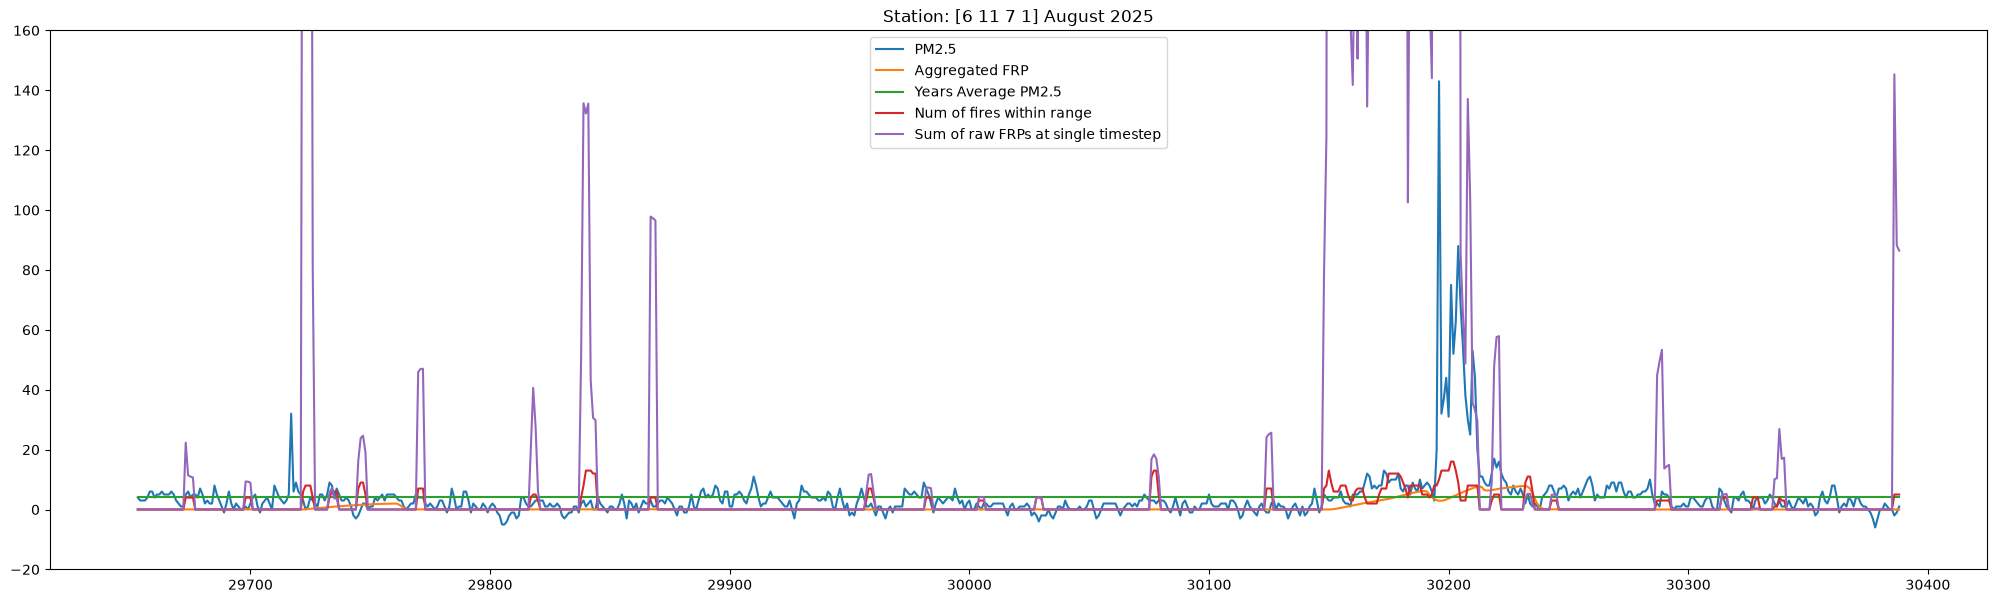

In [124]:
aqis_id = "6 11 7 1"
station_df = raw_df[raw_df['aqis_id'] == aqis_id]
plt.figure(figsize=(25, 7)) 
plt.ylim(-20, 160)
station_df["Sample Measurement"].plot(label="PM2.5")
station_df["collective_frp"].plot(label='Aggregated FRP')
station_df['last_years_avg'].plot(label='Years Average PM2.5')
station_df['num_fires_in_range'].plot(label='Num of fires within range')
station_df['sum_raw_frps'].plot(label='Sum of raw FRPs at single timestep')
plt.title(f"Station: [{aqis_id}] August 2025")
plt.legend()
plt.plot()

[]

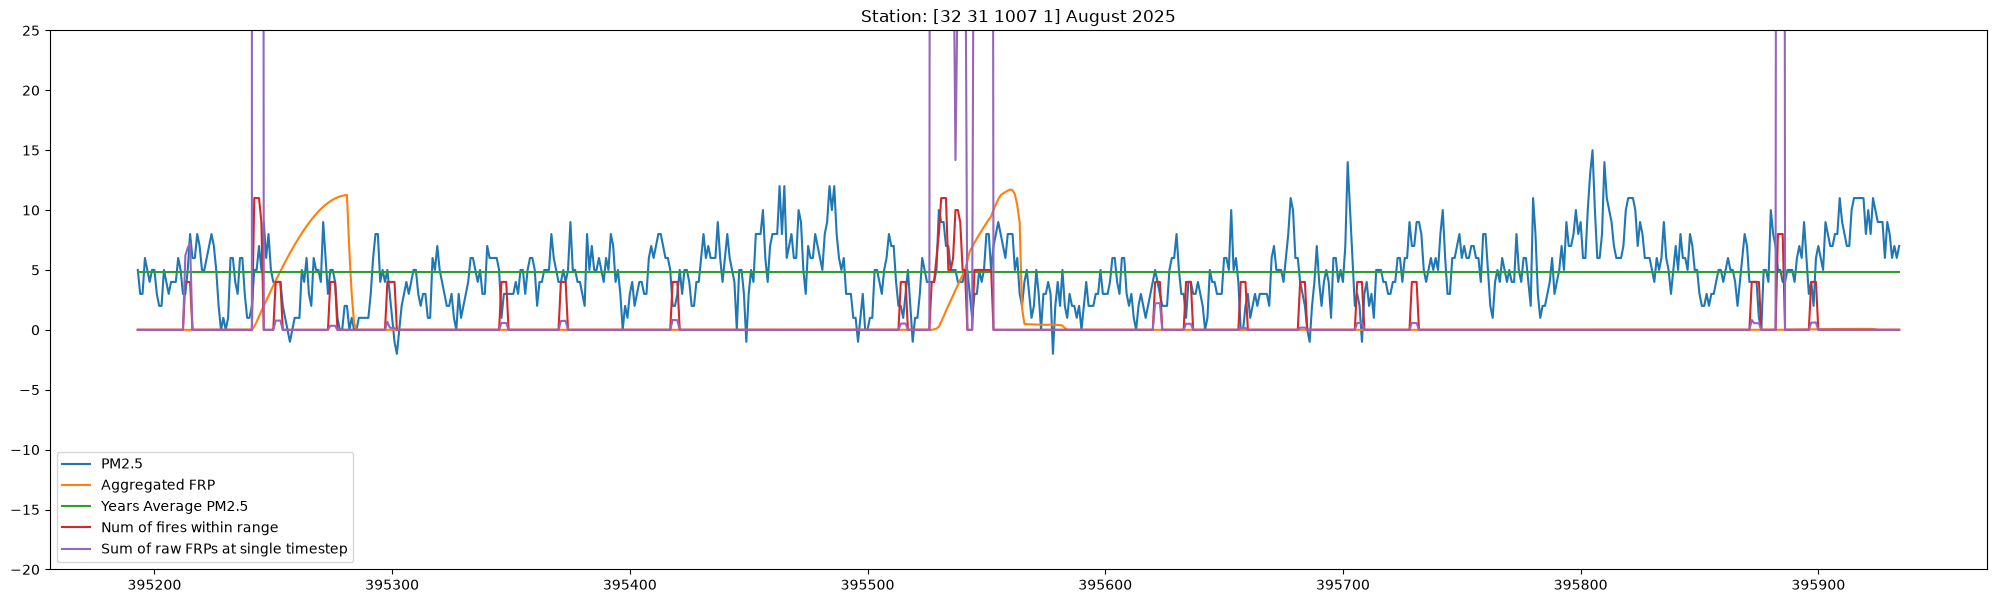

In [137]:
aqis_id = "32 31 1007 1"
station_df = raw_df[raw_df['aqis_id'] == aqis_id]
plt.figure(figsize=(25, 7)) 
plt.ylim(-20, 25)
station_df["Sample Measurement"].plot(label="PM2.5")
station_df["collective_frp"].plot(label='Aggregated FRP')
station_df['last_years_avg'].plot(label='Years Average PM2.5')
station_df['num_fires_in_range'].plot(label='Num of fires within range')
station_df['sum_raw_frps'].plot(label='Sum of raw FRPs at single timestep')
plt.title(f"Station: [{aqis_id}] August 2025")
plt.legend()
plt.plot()

[]

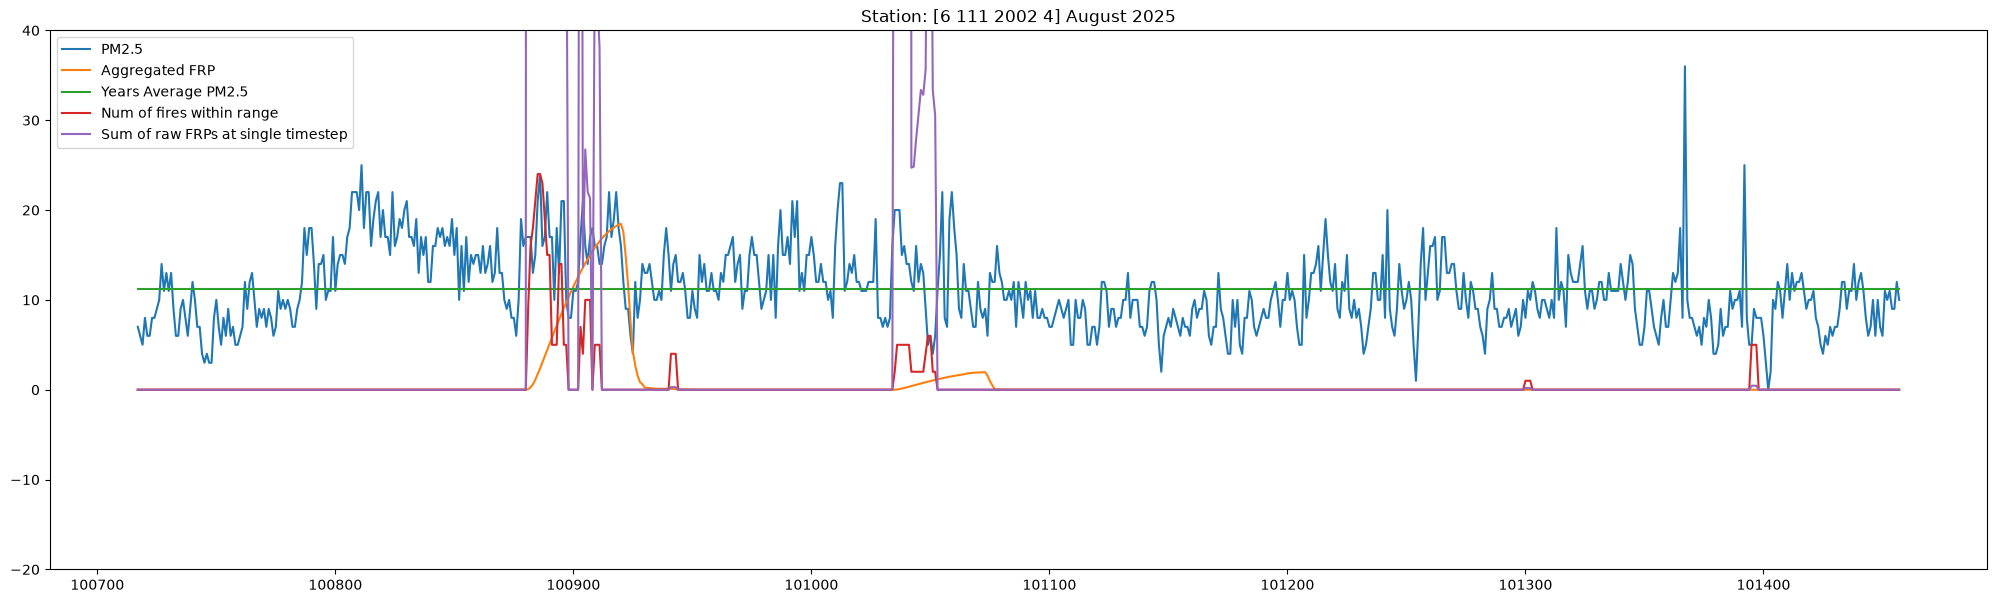

In [135]:
aqis_id = "6 111 2002 4"
station_df = raw_df[raw_df['aqis_id'] == aqis_id]
plt.figure(figsize=(25, 7)) 
plt.ylim(-20, 40)
station_df["Sample Measurement"].plot(label="PM2.5")
station_df["collective_frp"].plot(label='Aggregated FRP')
station_df['last_years_avg'].plot(label='Years Average PM2.5')
station_df['num_fires_in_range'].plot(label='Num of fires within range')
station_df['sum_raw_frps'].plot(label='Sum of raw FRPs at single timestep')
plt.title(f"Station: [{aqis_id}] August 2025")
plt.legend()
plt.plot()

[]

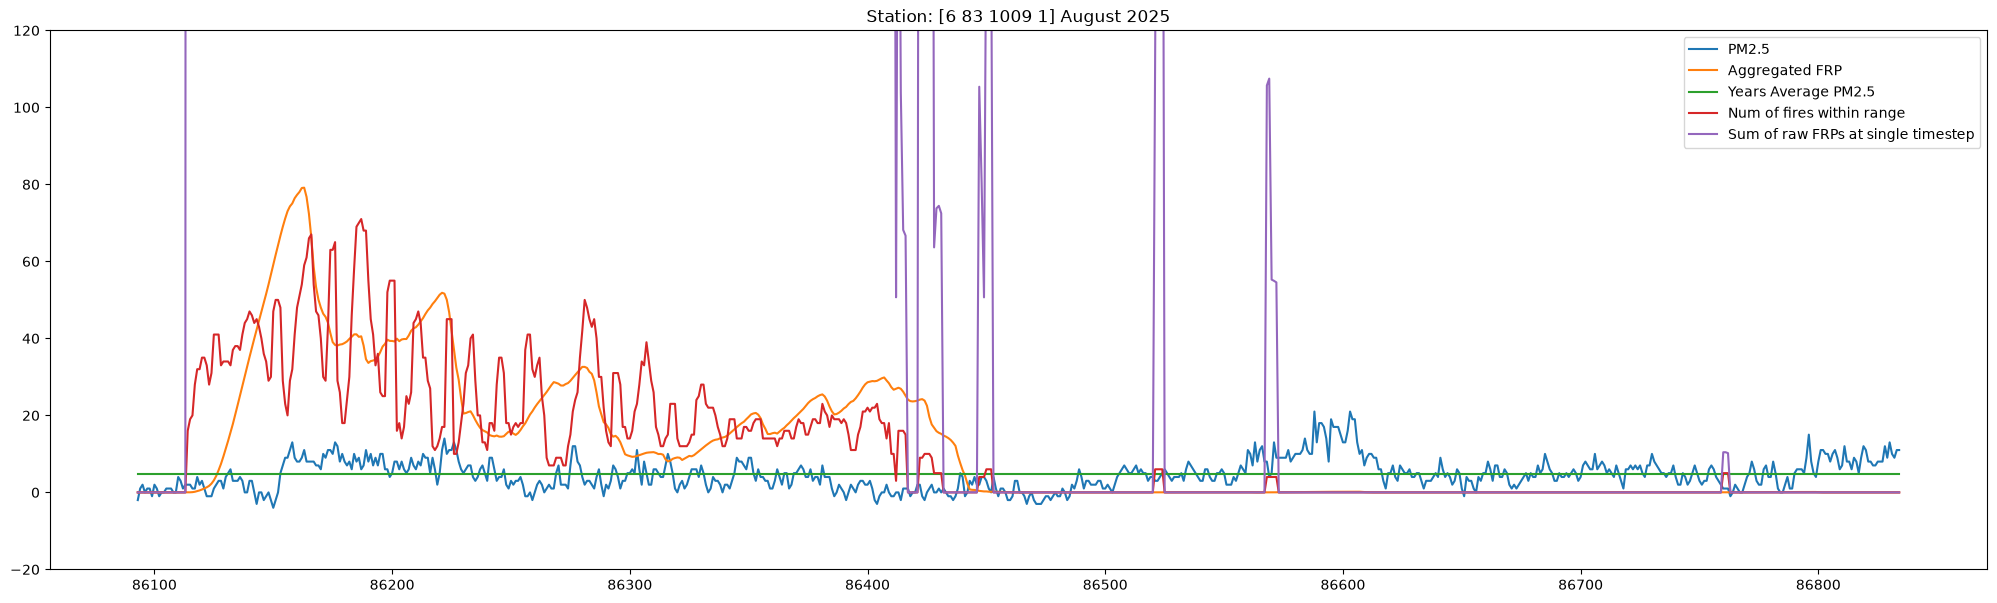

In [130]:
aqis_id = "6 83 1009 1"
station_df = raw_df[raw_df['aqis_id'] == aqis_id]
plt.figure(figsize=(25, 7)) 
plt.ylim(-20, 120)
station_df["Sample Measurement"].plot(label="PM2.5")
station_df["collective_frp"].plot(label='Aggregated FRP')
station_df['last_years_avg'].plot(label='Years Average PM2.5')
station_df['num_fires_in_range'].plot(label='Num of fires within range')
station_df['sum_raw_frps'].plot(label='Sum of raw FRPs at single timestep')
plt.title(f"Station: [{aqis_id}] August 2025")
plt.legend()
plt.plot()

[]

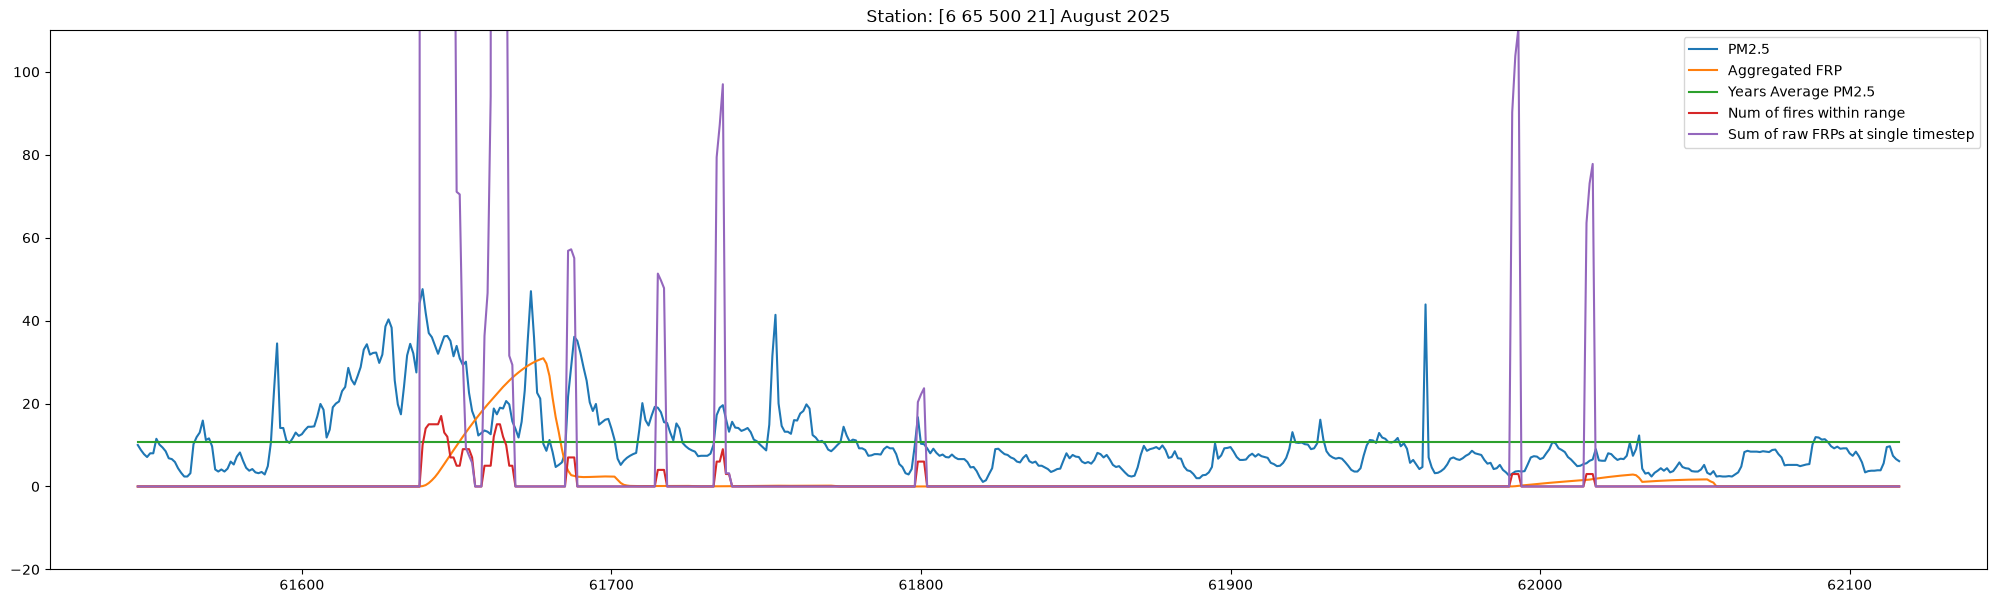

In [131]:
aqis_id = "6 65 500 21"
station_df = raw_df[raw_df['aqis_id'] == aqis_id]
plt.figure(figsize=(25, 7)) 
plt.ylim(-20, 110)
station_df["Sample Measurement"].plot(label="PM2.5")
station_df["collective_frp"].plot(label='Aggregated FRP')
station_df['last_years_avg'].plot(label='Years Average PM2.5')
station_df['num_fires_in_range'].plot(label='Num of fires within range')
station_df['sum_raw_frps'].plot(label='Sum of raw FRPs at single timestep')
plt.title(f"Station: [{aqis_id}] August 2025")
plt.legend()
plt.plot()

[]

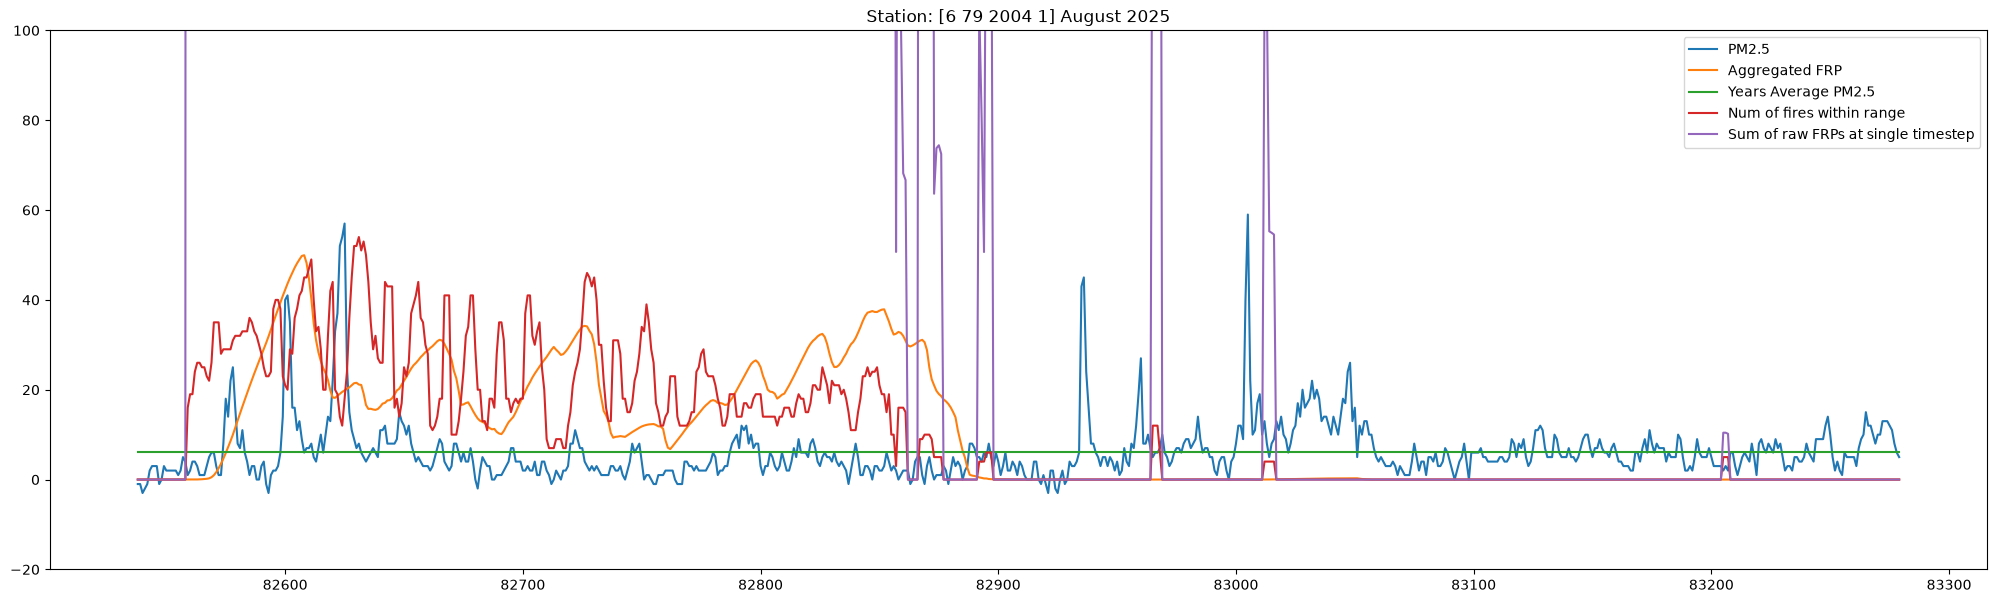

In [140]:
aqis_id = "6 79 2004 1"
station_df = raw_df[raw_df['aqis_id'] == aqis_id]
plt.figure(figsize=(25, 7)) 
plt.ylim(-20, 100)
station_df["Sample Measurement"].plot(label="PM2.5")
station_df["collective_frp"].plot(label='Aggregated FRP')
station_df['last_years_avg'].plot(label='Years Average PM2.5')
station_df['num_fires_in_range'].plot(label='Num of fires within range')
station_df['sum_raw_frps'].plot(label='Sum of raw FRPs at single timestep')
plt.title(f"Station: [{aqis_id}] August 2025")
plt.legend()
plt.plot()

[]

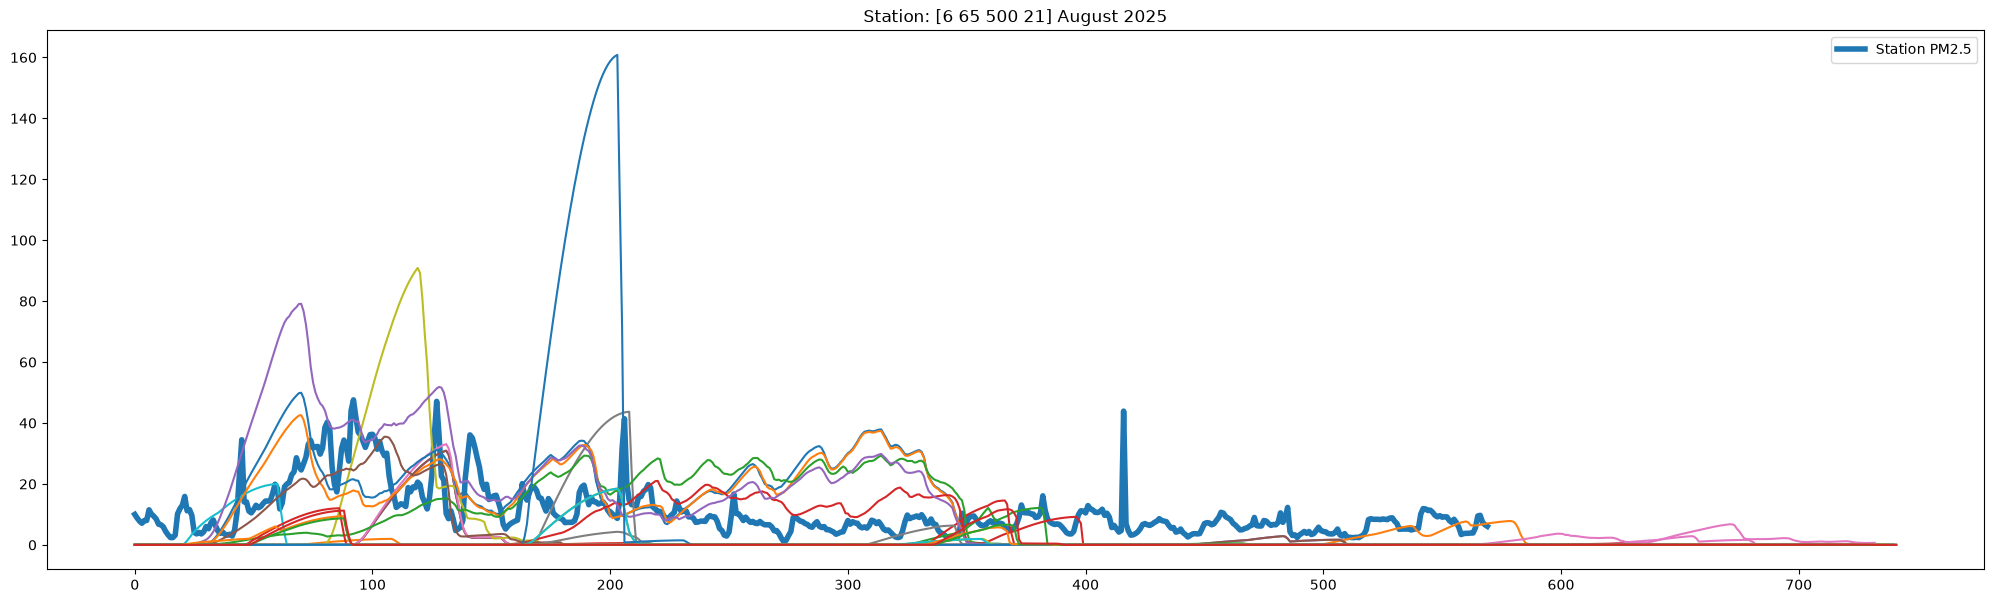

In [173]:
"""
[    '6 11 7 1',     '6 23 6 3',  '6 37 9035 1',   '6 65 500 1',
  '6 65 500 21',  '6 65 2007 3',  '6 65 8001 3',  '6 71 8001 3',
  '6 73 1017 3',  '6 79 2004 1',  '6 79 2007 1',  '6 79 2020 1',
  '6 79 8002 3',  '6 83 1009 1',  '6 83 3001 1',    '6 107 9 1',
    '6 111 9 3', '6 111 2002 3', '6 111 2002 4', '6 113 1003 3',
   '32 31 31 2', '32 31 1005 1', '32 31 1007 1']
"""

aqis_id = "6 65 500 21"
station_df = raw_df[raw_df['aqis_id'] == aqis_id]
plt.figure(figsize=(25, 7)) 
plt.plot(station_df["Sample Measurement"].values,label="Station PM2.5",linestyle='-', linewidth=4)
#plt.plot(station_df["collective_frp"].values,label="Collective FRP of the station")
for id in raw_df[raw_df['collective_frp'] > 5]['aqis_id'].unique():
    station_df = raw_df[raw_df['aqis_id'] == id]
    plt.plot(station_df["collective_frp"].values)
    
plt.title(f"Station: [{aqis_id}] August 2025")
plt.legend()
plt.plot()

[]

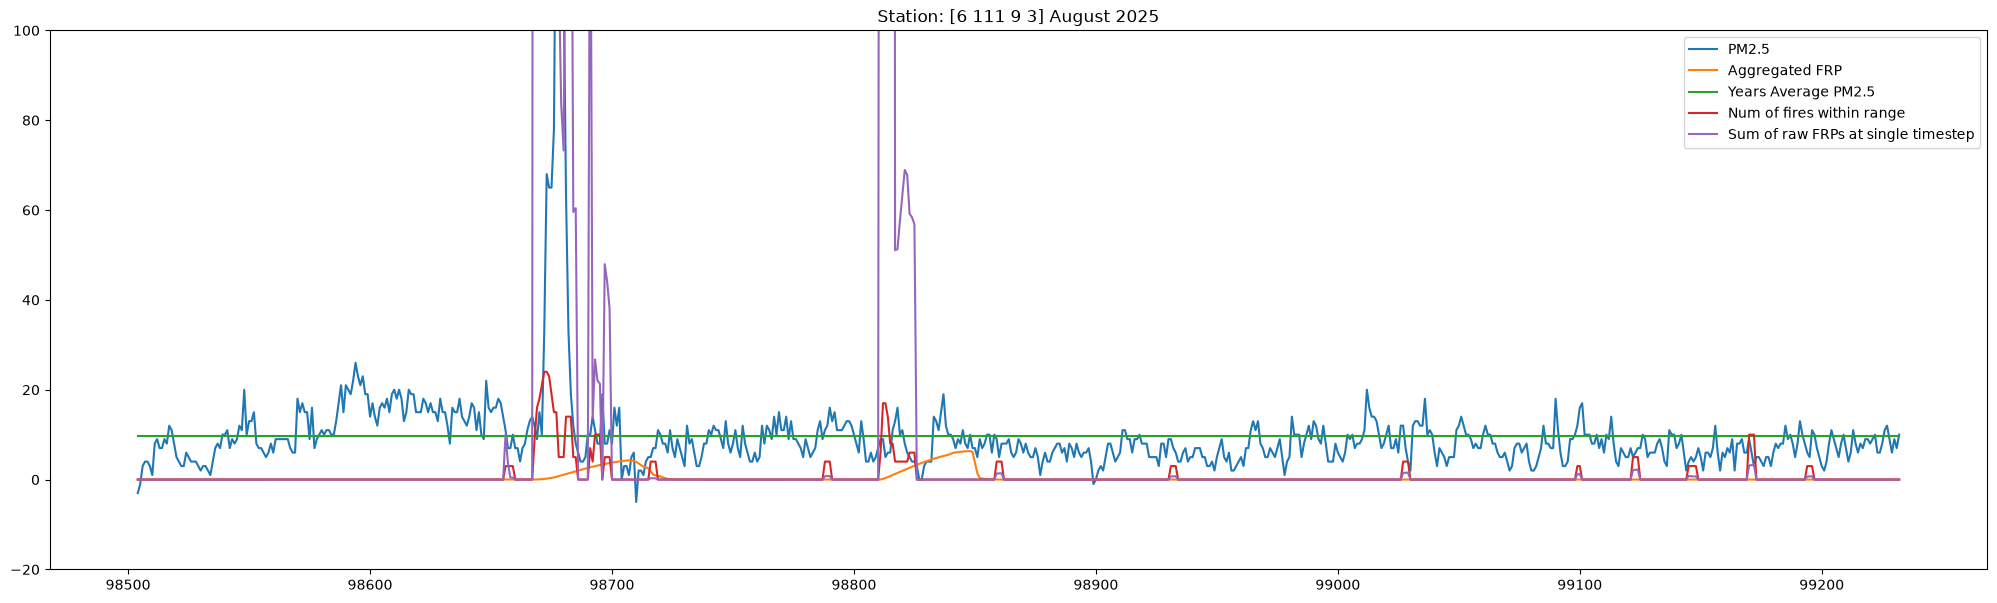

In [ ]:
aqis_id = "6 111 9 3"
station_df = raw_df[raw_df['aqis_id'] == aqis_id]
plt.figure(figsize=(25, 7)) 
plt.ylim(-20, 100)
station_df["Sample Measurement"].plot(label="PM2.5")
station_df["collective_frp"].plot(label='Aggregated FRP')
station_df['last_years_avg'].plot(label='Years Average PM2.5')
station_df['num_fires_in_range'].plot(label='Num of fires within range')
station_df['sum_raw_frps'].plot(label='Sum of raw FRPs at single timestep')
plt.title(f"Station: [{aqis_id}] August 2025")
plt.legend()
plt.plot()

In [63]:
raw_df[raw_df['collective_frp'] > 5]['aqis_id'].unique()

<ArrowStringArray>
[    '6 11 7 1',     '6 23 6 3',  '6 37 9035 1',   '6 65 500 1',
  '6 65 500 21',  '6 65 2007 3',  '6 65 8001 3',  '6 71 8001 3',
  '6 73 1017 3',  '6 79 2004 1',  '6 79 2007 1',  '6 79 2020 1',
  '6 79 8002 3',  '6 83 1009 1',  '6 83 3001 1',    '6 107 9 1',
    '6 111 9 3', '6 111 2002 3', '6 111 2002 4', '6 113 1003 3',
   '32 31 31 2', '32 31 1005 1', '32 31 1007 1']
Length: 23, dtype: str

In [36]:
station_df['date_hour']

0      2025-08-01 00:00
1      2025-08-01 01:00
2      2025-08-01 02:00
3      2025-08-01 03:00
4      2025-08-01 04:00
             ...       
737    2025-08-31 19:00
738    2025-08-31 20:00
739    2025-08-31 21:00
740    2025-08-31 22:00
741    2025-08-31 23:00
Name: date_hour, Length: 742, dtype: str

This is the one with the aqis_id in there that way you can do station based information

In [87]:
data_path = "/home/exouser/fireAirqaulity/training_data/X_train_3.csv"
column_names = ["u10", "v10","tp","t2m","sp","d2m","frp","cur_pm25","fut_pm25","near_fires","aqis_id"]

df = pd.read_csv(data_path, names=column_names, header=None)
df

,u10,v10,tp,t2m,sp,d2m,frp,cur_pm25,fut_pm25,near_fires,aqis_id
0,NaN,NaN,0.0,NaN,NaN,NaN,0.0,-0.747978,-0.747978,0,1 3 10 3
1,NaN,NaN,0.0,NaN,NaN,NaN,0.0,0.916824,2.016824,0,1 27 1 3
2,NaN,NaN,0.0,NaN,NaN,NaN,0.0,-5.872605,1.327395,0,1 49 1003 3
3,NaN,NaN,0.0,NaN,NaN,NaN,0.0,-3.942183,-1.742183,0,1 55 10 3
4,NaN,NaN,0.0,NaN,NaN,NaN,0.0,-0.364946,-0.664946,0,1 73 23 3
...,...,...,...,...,...,...,...,...,...,...,...
712470,1.559598,-0.632221,0.0,303.686829,87440.0,274.896851,0.0,-1.868506,-1.268506,0,56 37 7 3
712471,-1.627902,1.680279,0.0,303.811829,87440.0,272.146851,0.0,4.394865,3.994865,0,56 39 1006 3
712472,0.434598,4.055279,0.0,292.186829,75260.0,269.896851,0.0,4.879404,3.879404,0,56 39 1013 1
712473,-1.565402,0.680279,0.0,303.874329,87750.0,273.771851,0.0,2.458895,-0.741105,0,56 43 2 1


In [93]:
df[df["frp"] > 10]["aqis_id"].unique()

<ArrowStringArray>
[ '6 73 1017 3',  '6 83 1009 1',  '6 79 2004 1',  '6 79 2007 1',
  '6 83 3001 1',  '6 79 8002 3', '32 31 1007 1',  '6 71 8001 3',
  '6 65 2007 3',   '6 65 500 1',  '6 65 500 21',  '6 79 2020 1',
 '6 113 1003 3',  '6 65 8001 3', '6 111 2002 3', '6 111 2002 4',
  '6 37 9035 1',     '6 23 6 3']
Length: 18, dtype: str

[]

<Figure size 2500x700 with 0 Axes>

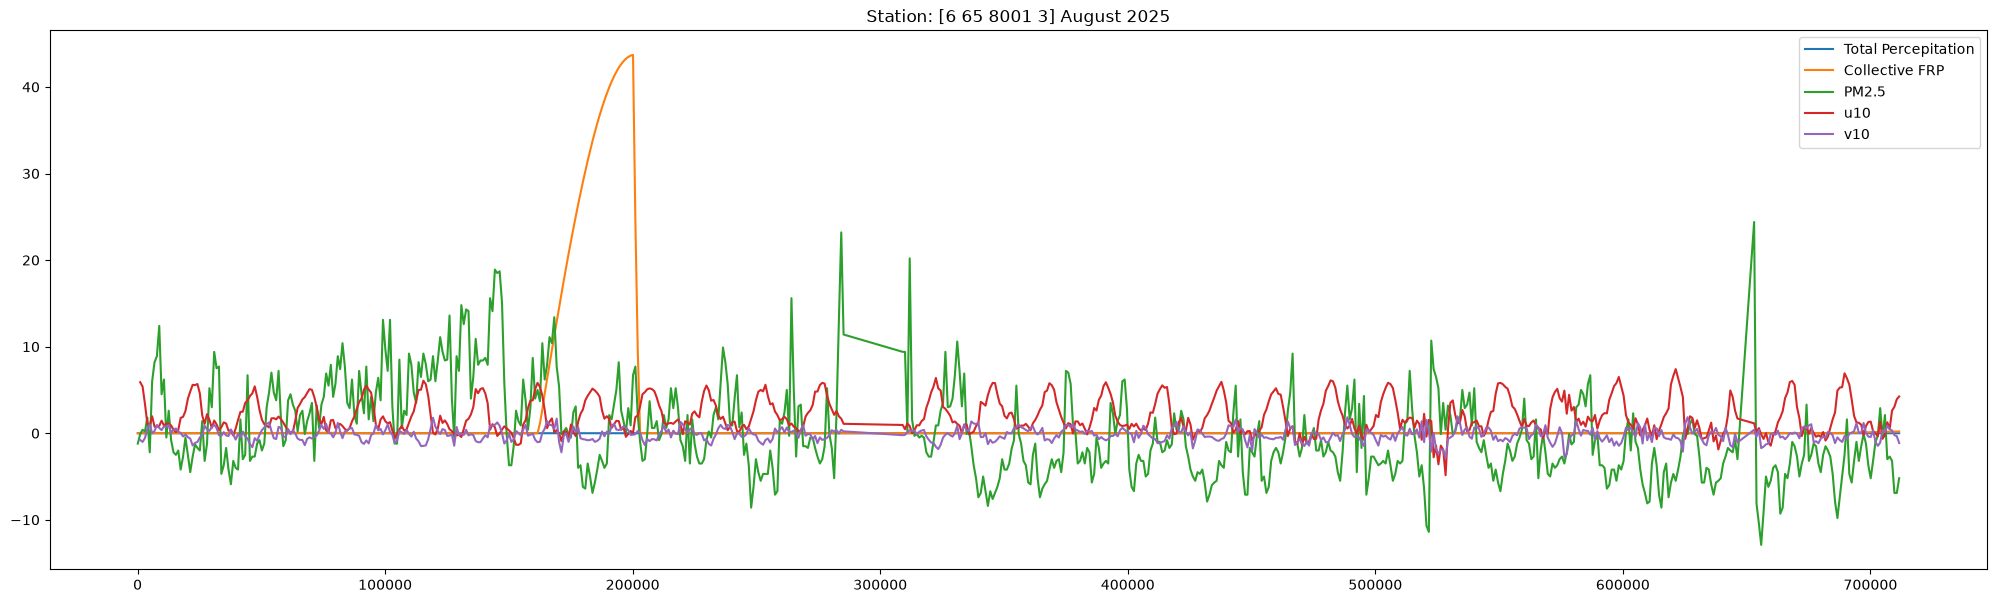

In [110]:
plt.figure(figsize=(25, 7)) 

aqis_id = "6 65 8001 3"
station_df = df[df['aqis_id'] == aqis_id]
plt.figure(figsize=(25, 7)) 
station_df["tp"].astype(float).plot(label='Total Percepitation')
station_df["frp"].astype(float).plot(label="Collective FRP")
station_df["cur_pm25"].astype(float).plot(label="PM2.5")
station_df["u10"].plot(label="u10")
station_df["v10"].plot(label="v10")
plt.title(f"Station: [{aqis_id}] August 2025")
plt.legend()
plt.plot()

[]

<Figure size 2500x700 with 0 Axes>

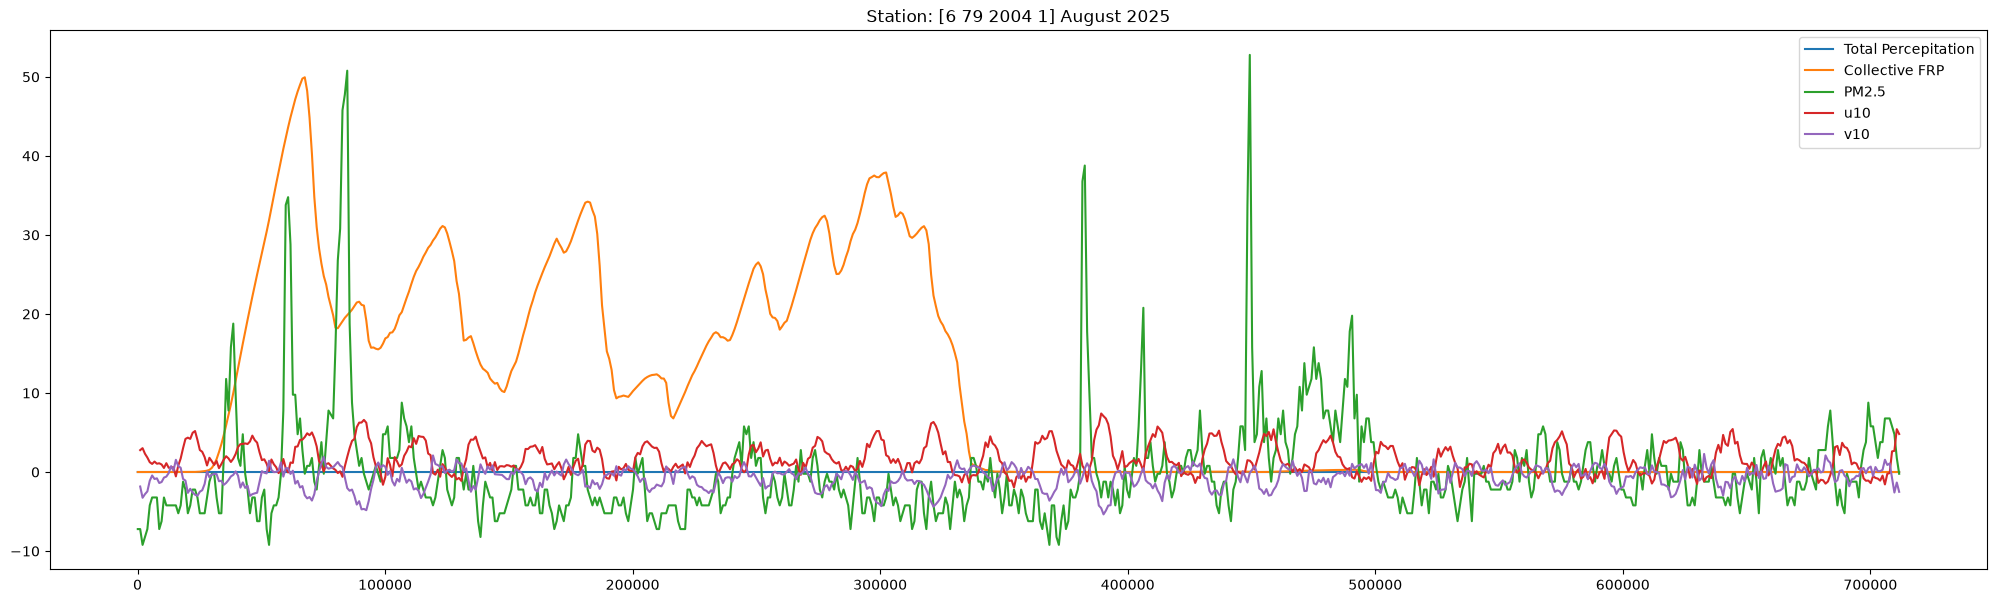

In [111]:
plt.figure(figsize=(25, 7)) 

aqis_id = "6 79 2004 1"
station_df = df[df['aqis_id'] == aqis_id]
plt.figure(figsize=(25, 7)) 
station_df["tp"].astype(float).plot(label='Total Percepitation')
station_df["frp"].astype(float).plot(label="Collective FRP")
station_df["cur_pm25"].astype(float).plot(label="PM2.5")
station_df["u10"].plot(label="u10")
station_df["v10"].plot(label="v10")
plt.title(f"Station: [{aqis_id}] August 2025")
plt.legend()
plt.plot()

[]

<Figure size 2500x700 with 0 Axes>

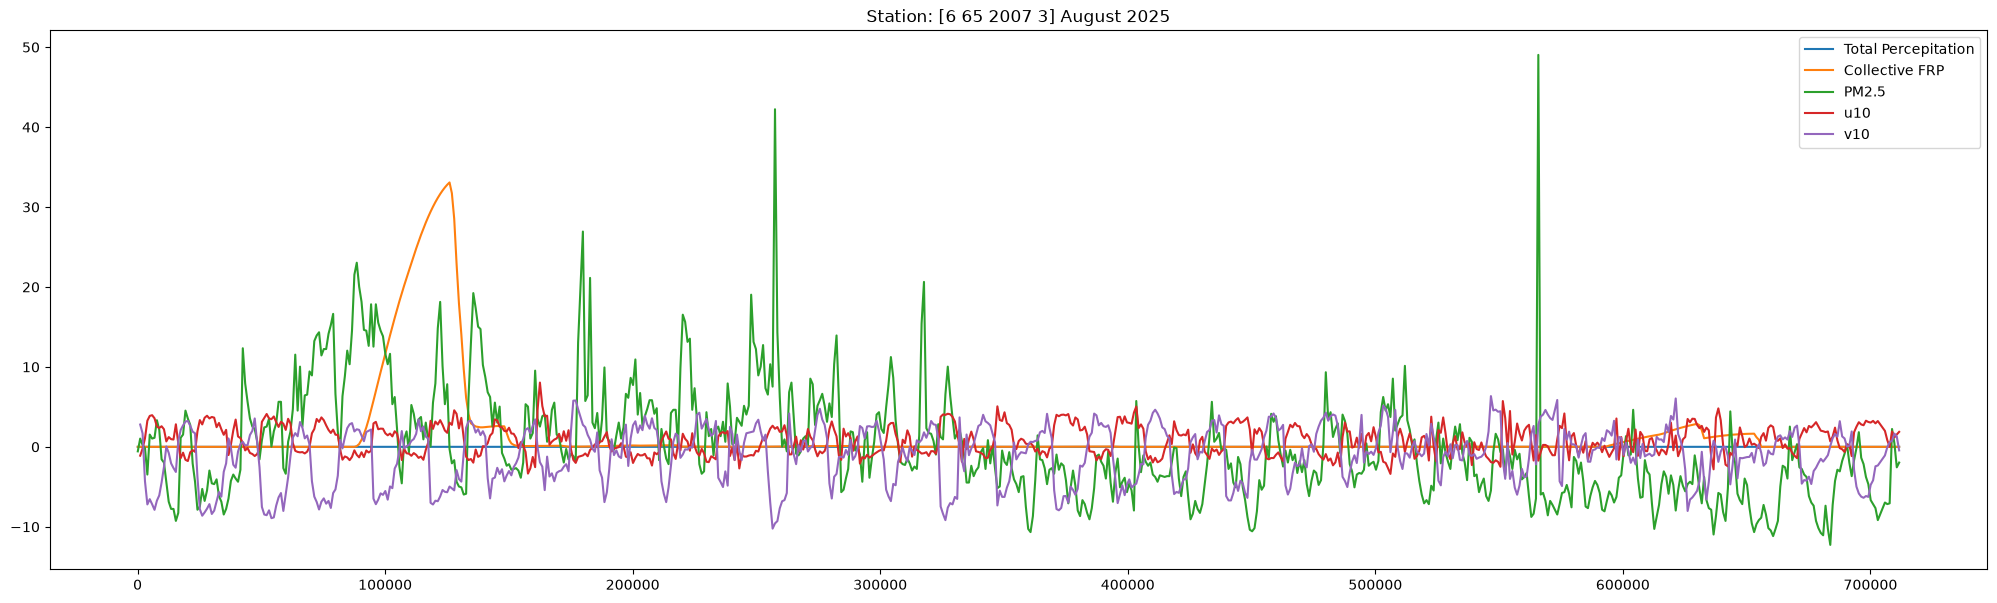

In [ ]:
plt.figure(figsize=(25, 7)) 

aqis_id = "6 65 2007 3"
station_df = df[df['aqis_id'] == aqis_id]
plt.figure(figsize=(25, 7)) 
station_df["tp"].astype(float).plot(label='Total Percepitation')
station_df["frp"].astype(float).plot(label="Collective FRP")
station_df["cur_pm25"].astype(float).plot(label="PM2.5")
station_df["u10"].plot(label="u10")
station_df["v10"].plot(label="v10")
plt.title(f"Station: [{aqis_id}] August 2025")
plt.legend()
plt.plot()

[]

<Figure size 2500x700 with 0 Axes>

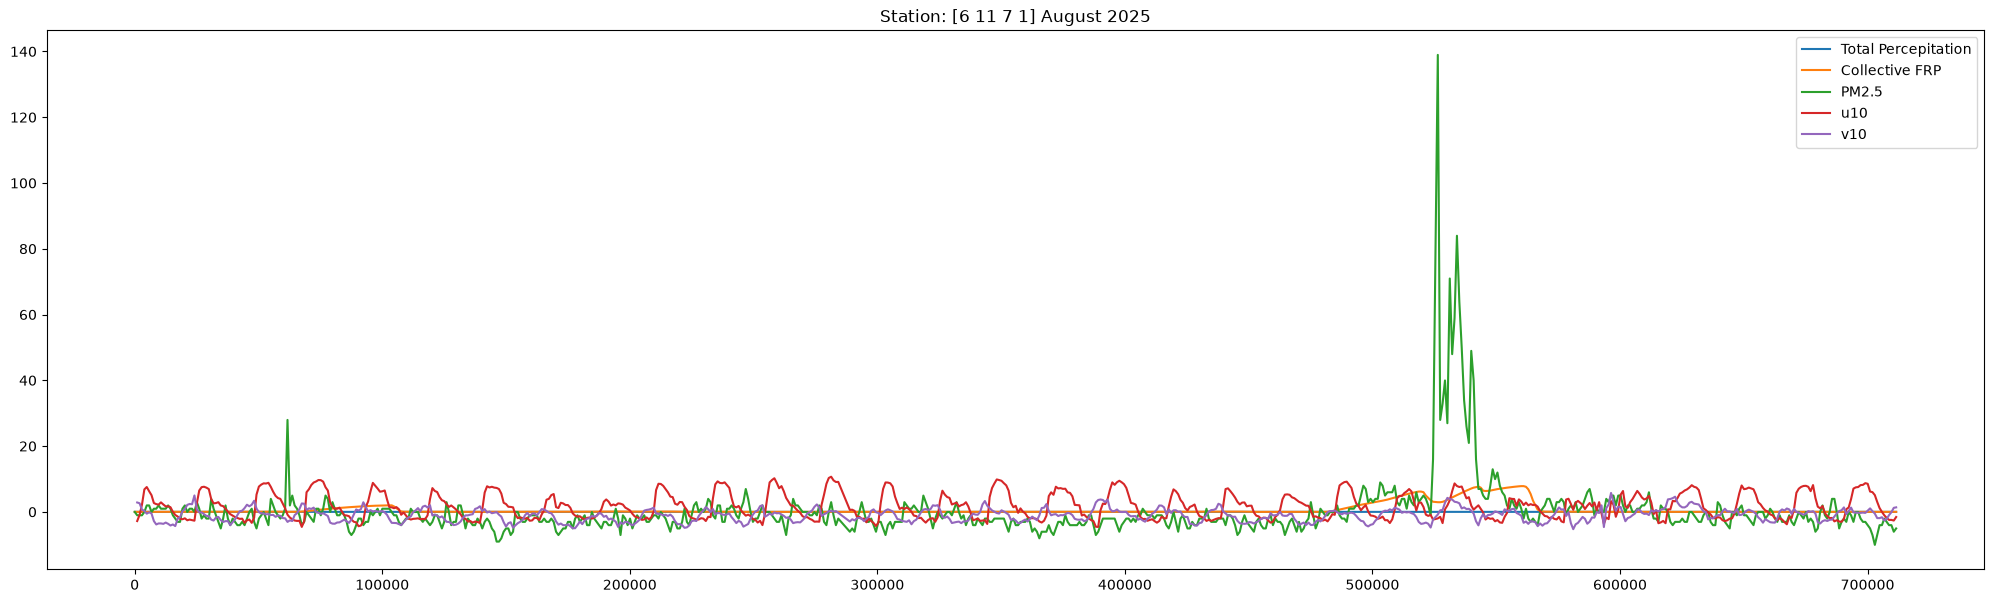

In [113]:
plt.figure(figsize=(25, 7)) 

aqis_id = "6 11 7 1"
station_df = df[df['aqis_id'] == aqis_id]
plt.figure(figsize=(25, 7)) 
station_df["tp"].astype(float).plot(label='Total Percepitation')
station_df["frp"].astype(float).plot(label="Collective FRP")
station_df["cur_pm25"].astype(float).plot(label="PM2.5")
station_df["u10"].plot(label="u10")
station_df["v10"].plot(label="v10")
plt.title(f"Station: [{aqis_id}] August 2025")
plt.legend()
plt.plot()

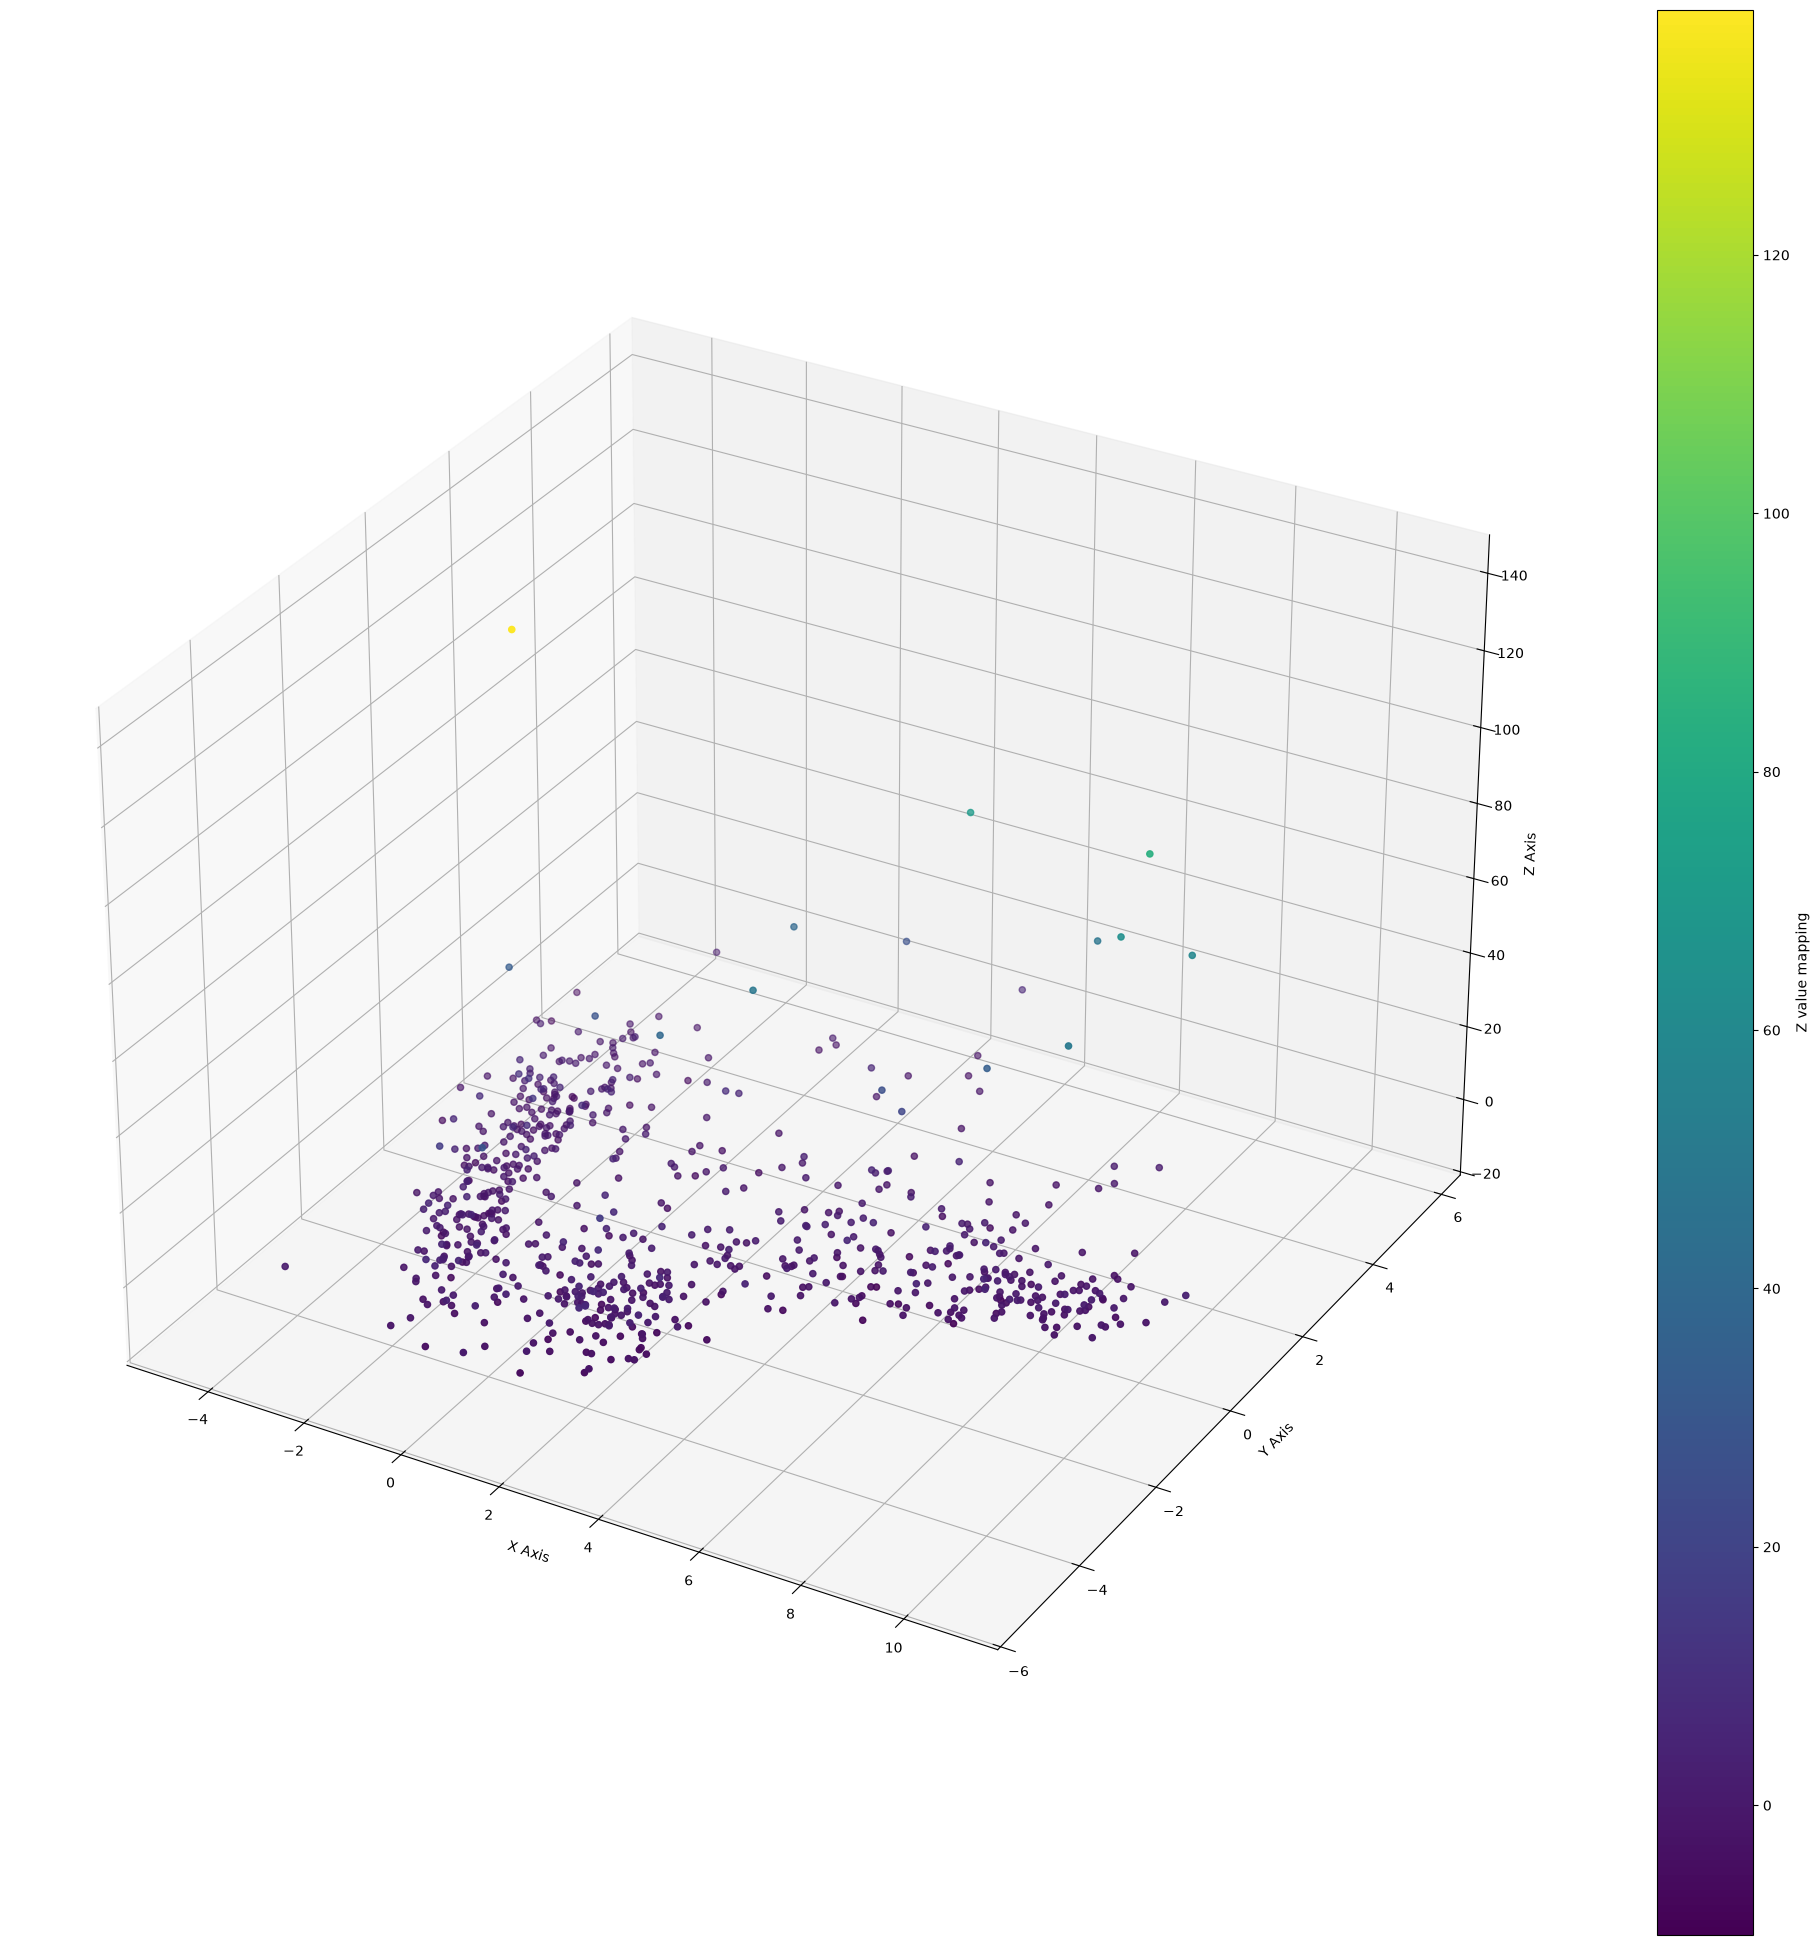

In [119]:
fig = plt.figure(figsize=(25, 25)) 
ax = fig.add_subplot(projection='3d')

# 3. Create the 3D scatter plot
aqis_id = "6 11 7 1"
station_df = df[df['aqis_id'] == aqis_id]
sc = ax.scatter(station_df['u10'], station_df['v10'], station_df['cur_pm25'], c=station_df['cur_pm25'], cmap='viridis', s=20)
# 4. Add labels and a colorbar
ax.set_xlabel('X Axis')
ax.set_ylabel('Y Axis')
ax.set_zlabel('Z Axis')
fig.colorbar(sc, ax=ax, label='Z value mapping')

plt.show()

# HRRR Smoke stuff

In [17]:
import xarray as xr
import numpy as np
ds = xr.open_dataset("/home/exouser/data/hrrr/20260801/subset_d9e49dd4__hrrr.t12z.wrfsfcf01.grib2", engine="cfgrib")
ds

<xarray.Dataset> Size: 38MB
Dimensions:            (y: 1059, x: 1799)
Coordinates:
    latitude           (y, x) float64 15MB ...
    longitude          (y, x) float64 15MB ...
    time               datetime64[ns] 8B ...
    step               timedelta64[ns] 8B ...
    heightAboveGround  float64 8B ...
    valid_time         datetime64[ns] 8B ...
Dimensions without coordinates: y, x
Data variables:
    unknown            (y, x) float32 8MB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-08T15:15 GRIB to CDM+CF via cfgrib-0.9.1...

In [22]:
ds.unknown.values * 10**9

array([[3.9999999e-02, 3.9999999e-02, 3.9999999e-02, ..., 3.9999999e-02,
        3.9999999e-02, 3.9999999e-02],
       [3.9999999e-02, 3.9999999e-02, 3.9999999e-02, ..., 3.9999999e-02,
        3.9999999e-02, 3.9999999e-02],
       [3.9999999e-02, 3.9999999e-02, 3.9999999e-02, ..., 3.9999999e-02,
        3.9999999e-02, 3.9999999e-02],
       ...,
       [1.1689715e-16, 1.1689715e-16, 1.1689715e-16, ..., 1.2000000e-01,
        1.6000000e-01, 1.2000000e-01],
       [1.1689715e-16, 1.1689715e-16, 1.1689715e-16, ..., 1.2000000e-01,
        1.2000000e-01, 1.2000000e-01],
       [1.1689715e-16, 1.1689715e-16, 1.1689715e-16, ..., 1.2000000e-01,
        1.2000000e-01, 1.2000000e-01]], shape=(1059, 1799), dtype=float32)

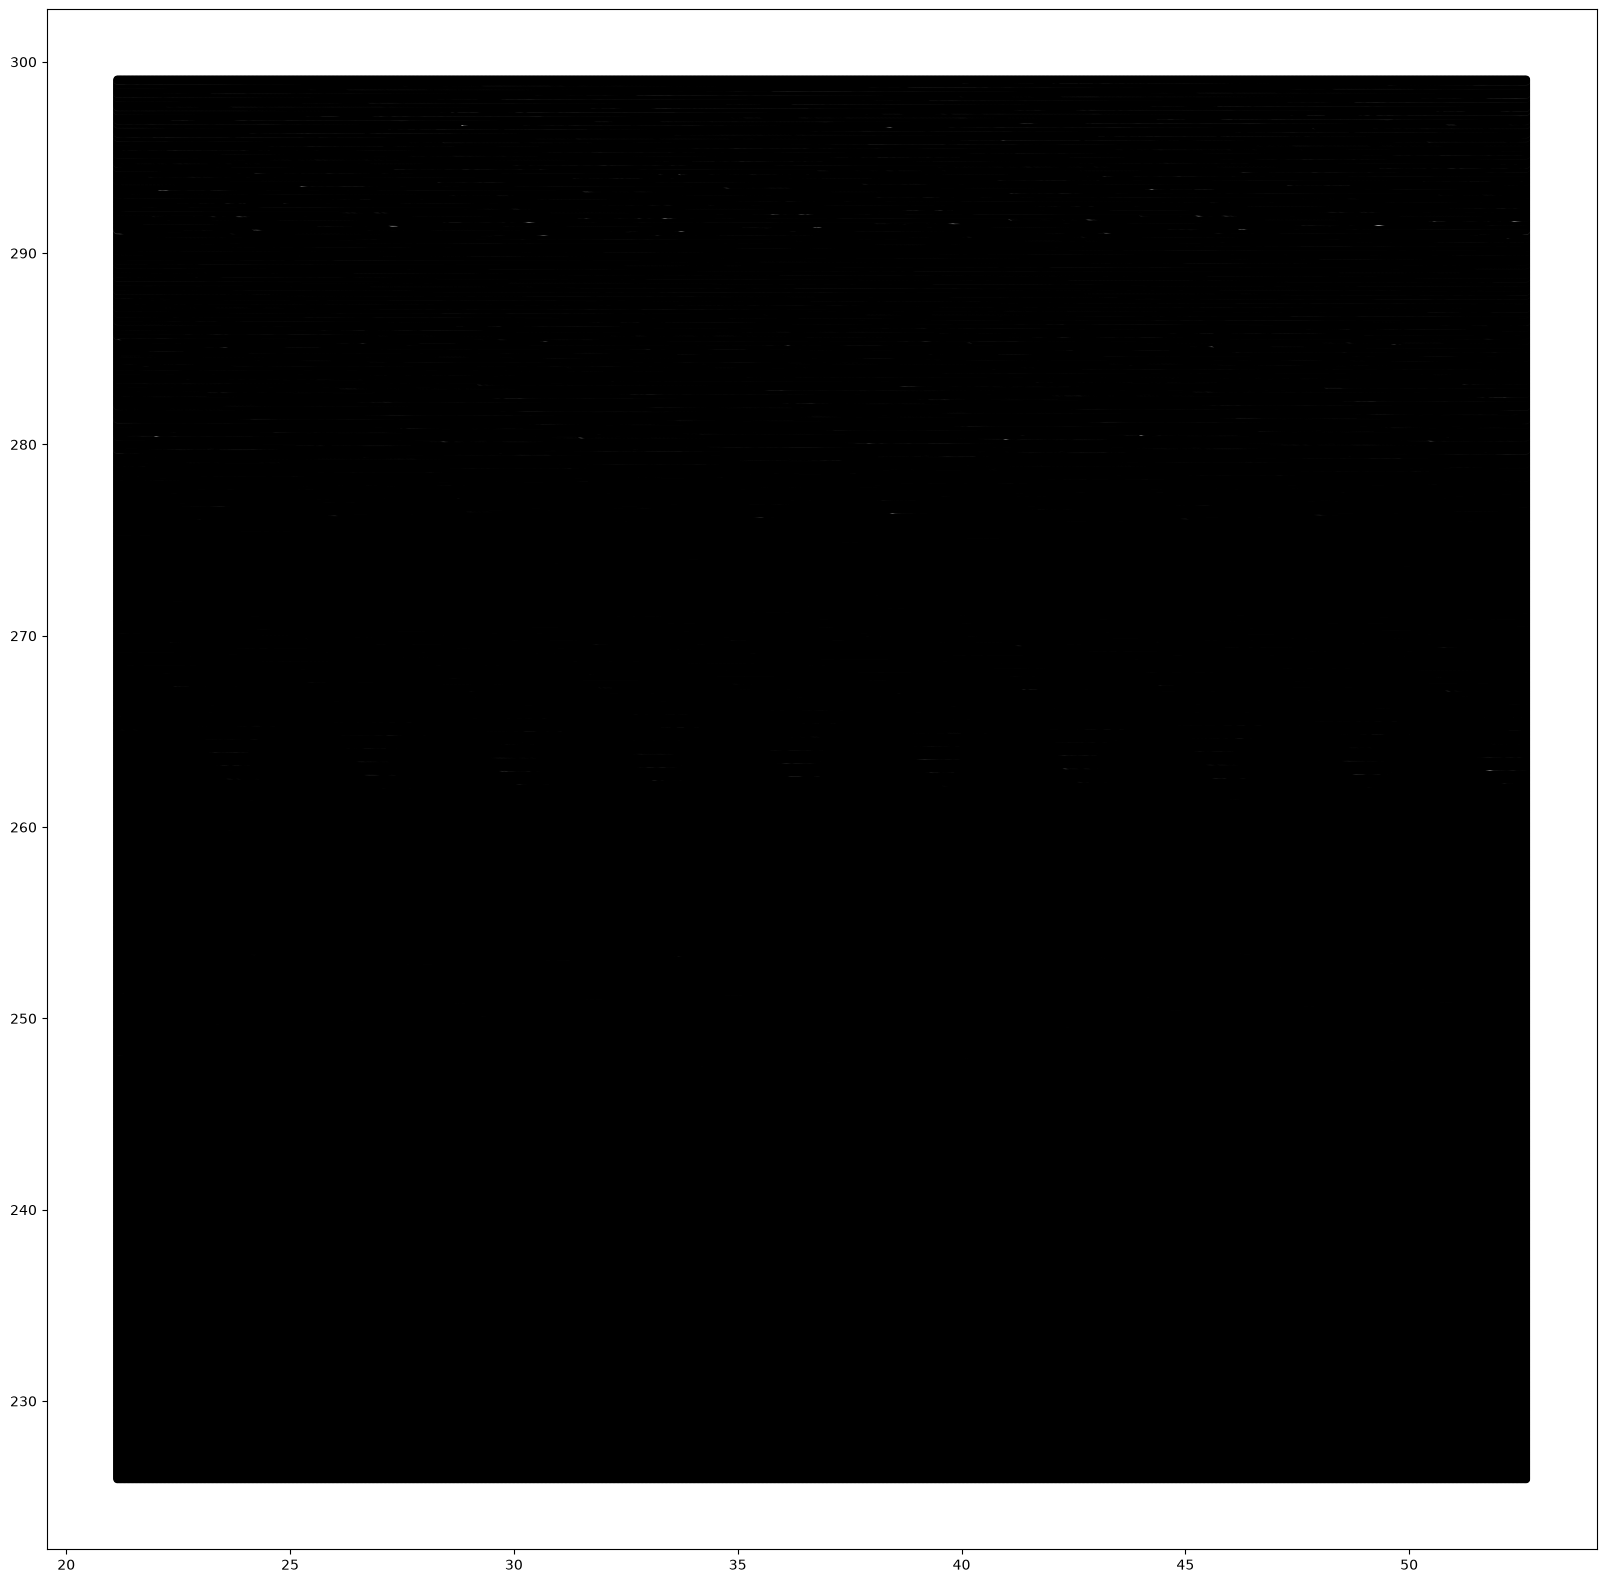

In [23]:
lonMax = ds.longitude.values.max()
lonMin = ds.longitude.values.min()
# Y
latMin = ds.latitude.values.min()
latMax = ds.latitude.values.max()


smoke = ds.unknown.values * 10**9
x = np.linspace(lonMin, lonMax, 1799)
y = np.linspace(latMin, latMax, 1059)
X, Y = np.meshgrid(y, x)
scatter_x = X.ravel()
scatter_y = Y.ravel()


plt.figure(figsize=(20, 20))
plt.scatter(scatter_x, scatter_y, c=smoke, cmap="gray", s=20,zorder=0)
plt.show()